In [ ]:
import pandas as pd

df = pd.read_excel(r"C:\Users\ASUS\Downloads\Group 1 - Egy - 3rd Year - 2025-2026 (1).Xlsx")
df.head()

,رقم الجلوس,Arabic name,English name,C Email
0,4.0,أبرار عصام حمدى الهواري,Abrar Essam Hamdy El Hawary,abrar.hamdy2301@alexmed.edu.eg
1,6.0,ابراهيم أحمد عطيه خليفه,Ibrahim Ahmed Attia Khalifa,ibrahim.ahmed2301@alexmed.edu.eg
2,13.0,إبراهيم عبد المنصف إبراهيم البوص,Ebrahim Abdelmonsef Ebrahim Elbous,ebrahim.abdelmonsef2301@alexmed.edu.eg
3,20.0,إبراهيم محمد إبراهيم مرسي,Ibrahim Mohamed Ibrahim morsy,ibrahim.mohamed2301@alexmed.edu.eg
4,21.0,إبراهيم محمد طلعت النجار,Ibrahim Mohammed Talaat Elnaggar,ibrahim.mohammed2301@alexmed.edu.eg


In [ ]:
print(df["رقم الجلوس"].isna().sum())

1


In [ ]:
missing_seats = df[df["رقم الجلوس"].isna()]
if len(missing_seats) > 0:
    print(missing_seats[["Arabic name", "English name", "C Email"]])

                         Arabic name  \
506  احمد محمد عبد الفتاح محمد السيد   

                                  English name  \
506  Ahmed mohamed abdelfattah mohamed elsayed   

                              C Email  
506  ahmed.mohamed2313@alexmed.edu.eg  


In [ ]:
student_email = "ahmed.mohamed2313@alexmed.edu.eg"
df = df[df["C Email"] != student_email]

In [ ]:
print(df["رقم الجلوس"].isna().sum())

0


In [ ]:
df["رقم الجلوس"] = df["رقم الجلوس"].astype(int)
df.head()

,رقم الجلوس,Arabic name,English name,C Email
0,4,أبرار عصام حمدى الهواري,Abrar Essam Hamdy El Hawary,abrar.hamdy2301@alexmed.edu.eg
1,6,ابراهيم أحمد عطيه خليفه,Ibrahim Ahmed Attia Khalifa,ibrahim.ahmed2301@alexmed.edu.eg
2,13,إبراهيم عبد المنصف إبراهيم البوص,Ebrahim Abdelmonsef Ebrahim Elbous,ebrahim.abdelmonsef2301@alexmed.edu.eg
3,20,إبراهيم محمد إبراهيم مرسي,Ibrahim Mohamed Ibrahim morsy,ibrahim.mohamed2301@alexmed.edu.eg
4,21,إبراهيم محمد طلعت النجار,Ibrahim Mohammed Talaat Elnaggar,ibrahim.mohammed2301@alexmed.edu.eg


In [ ]:
df.to_excel(r"C:\Users\ASUS\Downloads\Group 1 - Egy - 3rd Year - 2025-2026 (1)_updated.xlsx", index=False)
print("pdated'")
df.head()

pdated'


,رقم الجلوس,Arabic name,English name,C Email
0,4,أبرار عصام حمدى الهواري,Abrar Essam Hamdy El Hawary,abrar.hamdy2301@alexmed.edu.eg
1,6,ابراهيم أحمد عطيه خليفه,Ibrahim Ahmed Attia Khalifa,ibrahim.ahmed2301@alexmed.edu.eg
2,13,إبراهيم عبد المنصف إبراهيم البوص,Ebrahim Abdelmonsef Ebrahim Elbous,ebrahim.abdelmonsef2301@alexmed.edu.eg
3,20,إبراهيم محمد إبراهيم مرسي,Ibrahim Mohamed Ibrahim morsy,ibrahim.mohamed2301@alexmed.edu.eg
4,21,إبراهيم محمد طلعت النجار,Ibrahim Mohammed Talaat Elnaggar,ibrahim.mohammed2301@alexmed.edu.eg


In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time
import random
import urllib3

# Suppress the insecure request warnings
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

TARGET_URL = "https://med.alexu.edu.eg/results/level_results.php?level_id=237"
INPUT_NAME = "student_number"

# The magic headers from your high school script
HEADERS = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/114.0.0.0 Safari/537.36',
    'Referer': TARGET_URL,
    'Origin': 'https://med.alexu.edu.eg',
    'Content-Type': 'application/x-www-form-urlencoded'
}

def extract_student_data(file_path):
    df = pd.read_excel(file_path)
    all_students_data = []

    # Testing with only the first 10 rows
    test_df = df.head(506)

    for index, row in test_df.iterrows():
        seat_number = int(row.iloc[0])
        print(f"Fetching data for Seat Number: {seat_number}...")

        max_retries = 3
        success = False

        for attempt in range(max_retries):
            try:
                # Open a new session for each attempt just like the high school script
                session = requests.Session()
                session.headers.update(HEADERS)

                get_response = session.get(TARGET_URL, verify=False, timeout=20)
                soup_get = BeautifulSoup(get_response.content, 'html.parser')

                csrf_input = soup_get.find('input', {'name': 'csrf_token'})
                if not csrf_input:
                    print(f"Attempt {attempt + 1}: Token not found. Retrying in 5 seconds...")
                    time.sleep(5)
                    continue

                payload = {
                    'csrf_token': csrf_input['value'],
                    INPUT_NAME: seat_number
                }

                post_response = session.post(TARGET_URL, data=payload, verify=False, timeout=20)

                if post_response.status_code == 200:
                    soup_post = BeautifulSoup(post_response.content, 'html.parser')
                    tables = soup_post.find_all('table')

                    if tables:
                        target_table = tables[0]
                        rows = target_table.find_all('tr')
                        student_record = {'Seat_Number': seat_number}

                        for tr in rows:
                            cols = tr.find_all('td')
                            if len(cols) >= 3:
                                subject = cols[0].text.strip()
                                score = cols[2].text.strip()
                                if subject and subject != '*':
                                    student_record[subject] = score
                            elif len(cols) == 2:
                                key = cols[0].text.strip()
                                value = cols[1].text.strip()
                                if key:
                                    student_record[key] = value

                        all_students_data.append(student_record)
                        print(f"Successfully extracted data for Seat Number: {seat_number}")
                        success = True

                        # Random delay between requests to avoid bans
                        time.sleep(random.uniform(3, 6))
                        break
                    else:
                        print(f"Attempt {attempt + 1}: Table not found. Token might be expired.")
                        time.sleep(10)

            except Exception as e:
                # Catch the timeout and retry instead of crashing
                print(f"Attempt {attempt + 1} failed for {seat_number}: {type(e).__name__}")
                time.sleep(5)

        if not success:
            print(f"Skipping {seat_number} after {max_retries} failed attempts.")

        # Save backup every 20 records
        if len(all_students_data) > 0 and len(all_students_data) % 20 == 0:
            pd.DataFrame(all_students_data).to_csv("results_backup2.csv", index=False)
            print("Backup saved.")

    if all_students_data:
        final_df = pd.DataFrame(all_students_data)
        final_df.to_csv("medical.csv", index=False)
        print("Data extraction completed. Saved to medical_students_results.csv")

if __name__ == "__main__":
    # Update this to your excel file name
    extract_student_data(r"C:\Users\ASUS\Downloads\Group 1 - Egy - 3rd Year - 2025-2026 (1)_updated.xlsx")


Fetching data for Seat Number: 4...
Successfully extracted data for Seat Number: 4
Fetching data for Seat Number: 6...
Successfully extracted data for Seat Number: 6
Fetching data for Seat Number: 13...
Successfully extracted data for Seat Number: 13
Fetching data for Seat Number: 20...
Successfully extracted data for Seat Number: 20
Fetching data for Seat Number: 21...
Successfully extracted data for Seat Number: 21
Fetching data for Seat Number: 23...
Successfully extracted data for Seat Number: 23
Fetching data for Seat Number: 24...
Successfully extracted data for Seat Number: 24
Fetching data for Seat Number: 29...
Successfully extracted data for Seat Number: 29
Fetching data for Seat Number: 32...
Successfully extracted data for Seat Number: 32
Fetching data for Seat Number: 34...
Successfully extracted data for Seat Number: 34
Fetching data for Seat Number: 36...
Successfully extracted data for Seat Number: 36
Fetching data for Seat Number: 37...
Successfully extracted data for 

In [ ]:
df = pd.read_csv(r"medical.csv")

df_clean = df.copy()

# Convert 'النسبة' to numeric, coercing errors to NaN
df_clean['النسبة'] = pd.to_numeric(df_clean['النسبة'], errors='coerce')

# Remove rows where 'النسبة' is NaN
df_clean = df_clean.dropna(subset=['النسبة'])

# Sort by percentage (النسبة) in descending order (highest first)
df_sorted = df_clean.sort_values(by='النسبة', ascending=False)

# Identify failing students - check multiple possible column names
grade_col = None
for col in df_sorted.columns:
    if 'تقدير' in col or 'التقدير' in col:
        grade_col = col
        break

if grade_col:
    df_failed = df_sorted[df_sorted[grade_col].isin(['راسب', 'Fail', 'غ ب'])]
    df_passed = df_sorted[~df_sorted[grade_col].isin(['راسب', 'Fail', 'غ ب'])]
else:
    # If no grade column found, treat all as passing
    df_passed = df_sorted
    df_failed = pd.DataFrame()

# Combine: passing students first, then failing students
df_final = pd.concat([df_passed, df_failed])

# Add a ranking column
df_final['الترتيب'] = range(1, len(df_final) + 1)

# Reset index
df_final = df_final.reset_index(drop=True)

# Display results - find the correct column names
seat_col = None
for col in df_final.columns:
    if 'Seat' in col or 'seat' in col or 'رقم' in col:
        seat_col = col
        break

credit_col = None
for col in df_final.columns:
    if 'credit' in col.lower() or 'نقطة' in col:
        credit_col = col
        break

# Print results
print("\n" + "="*80)
print("SORTED STUDENTS BY PERCENTAGE (Highest to Lowest)")
print("="*80)

# Create display dataframe with available columns
display_cols = []
if seat_col:
    display_cols.append(seat_col)
if 'النسبة' in df_final.columns:
    display_cols.append('النسبة')
if grade_col:
    display_cols.append(grade_col)
if credit_col:
    display_cols.append(credit_col)
display_cols.append('الترتيب')

print(df_final[display_cols])

print("\n" + "="*80)
print(f"Total Students: {len(df_final)}")
print(f"Passing Students: {len(df_passed)}")
print(f"Failing Students: {len(df_failed)}")
print("="*80)

# Show column names for reference
print("\nAll column names in your data:")
for i, col in enumerate(df_final.columns):
    print(f"{i+1}. '{col}'")

# Save to CSV
df_final.to_csv(r"medical_sorted_by_percentage.csv", index=False)
print("\n File saved as 'medical_sorted_by_percentage.csv'")

# Save to Excel
try:
    df_final.to_excel(r"medical_sorted_by_percentage.xlsx", index=False)
    print(" File also saved as 'medical_sorted_by_percentage.xlsx'")
except:
    print(" Could not save as Excel (openpyxl may not be installed)")

# Show failing students
if len(df_failed) > 0 and grade_col:
    print("\n" + "="*80)
    print("FAILING STUDENTS:")
    print("="*80)
    fail_cols = []
    if seat_col:
        fail_cols.append(seat_col)
    if 'النسبة' in df_failed.columns:
        fail_cols.append('النسبة')
    if grade_col:
        fail_cols.append(grade_col)
    if credit_col:
        fail_cols.append(credit_col)
    print(df_failed[fail_cols])
else:
    print("\n No failing students found!")


SORTED STUDENTS BY PERCENTAGE (Highest to Lowest)
     Seat_Number    النسبة    التقدير  GENERAL MEDICINE\ncredit point\n6  \
0            767  0.972381  Excellent                                  6   
1            536  0.971429  Excellent                                  6   
2            930  0.970476  Excellent                                  6   
3            864  0.968571  Excellent                                  6   
4            794  0.967619  Excellent                                  6   
..           ...       ...        ...                                ...   
479          696  0.705714       Good                                  6   
480          277  0.704762       Good                                  6   
481          625  0.696190       Good                                  6   
482           86  0.676667       Good                                  6   
483          680  0.656190       Good                                  6   

     الترتيب  
0          1  
1     

In [2]:
import pandas as pd

df= pd.read_csv(r"medical.csv")
df.head(14)

,Seat_Number,GENERAL MEDICINE\nend of round&Clinical\n90,GENERAL MEDICINE\nMCQ\n60,General medicine\nTotal \nModule\n150,GENERAL MEDICINE\nGrade averge,GENERAL MEDICINE\ncredit point\n6,General surgery\nCLINICAL STATIONS\n45,General surgery\nend of round\n45,General surgery\nMCQ\n60,General surgery\nTotal \nModule\n150,...,RESEARCH III\nAssignment\n20,RESEARCH III\nPractical \n45,RESEARCH III\nend of semester\n60,RESEARCH III\nTotal \nModule\n150,RESEARCH III\nGrade averge,RESEARCH III\ncredit\n point\n6,Total\n525,النسبة,التقدير,credit\n point
0,4,77,41,118,Very Good,6,42,39,56,137,...,17,27,47,111,Good,6,412,0.7847619047619,Very Good,21
1,6,64.5,43,104.5,Good,6,41,32,55,128,...,2,20.25,39,76.25,Fail,0,راسب,راسب,راسب,15
2,13,84.5,52,136.5,Excellent,6,44,45,55,144,...,20,40.75,53,136.75,Excellent,6,487.25,0.92809523809524,Excellent,21
3,20,76.5,49,125.5,Very Good,6,42,44,54,140,...,20,40.5,58,141.5,Excellent,6,476,0.90666666666667,Excellent,21
4,21,76,45,121,Very Good,6,42,45,56,143,...,20,37.5,55,134.5,Excellent,6,468.5,0.89238095238095,Excellent,21
5,23,70.5,43,113.5,Very Good,6,39,41,54,134,...,11,26.5,52,108.5,Good,6,419,0.79809523809524,Very Good,21
6,24,80,46,126,Very Good,6,44,44,55,143,...,18,36.25,51,127.25,Very Good,6,454.25,0.8652380952381,Excellent,21
7,29,78.5,44,122.5,Very Good,6,42,42,57,141,...,16,35.5,50,122.5,Very Good,6,443,0.84380952380952,Very Good,21
8,32,77.5,49,126.5,Very Good,6,42,42,53,137,...,16,41.25,55,133.25,Excellent,6,459.75,0.87571428571429,Excellent,21
9,34,77,48,125,Very Good,6,41,41,54,136,...,18,31.25,53,123.25,Very Good,6,441.25,0.84047619047619,Very Good,21


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
print("PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY")
print("=" * 70)

print("Dataset shape:", df.shape)
print("Number of records:", len(df))

print("\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {repr(col)}")

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

display(df.head())


PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY
Dataset shape: (501, 29)
Number of records: 501

Column names:
1. 'Seat_Number'
2. 'GENERAL MEDICINE\nend of round&Clinical\n90'
3. 'GENERAL MEDICINE\nMCQ\n60'
4. 'General medicine\nTotal \nModule\n150'
5. 'GENERAL MEDICINE\nGrade averge'
6. 'GENERAL MEDICINE\ncredit point\n6'
7. 'General surgery\nCLINICAL STATIONS\n45'
8. 'General surgery\nend of round\n45'
9. 'General surgery\nMCQ\n60'
10. 'General surgery\nTotal \nModule\n150'
11. 'General surgery\nGrade averge'
12. 'General surgery\n credit point'
13. 'INVESTIGATIVE MEDICINE\nRADIOLOGY\n22'
14. 'INVESTIGATIVE MEDICINE\nCLINICAL PATHOLOGY\n23'
15. 'INVESTIGATIVE MEDICINE\nMCQ\n30'
16. 'INVESTIGATIVE MEDICINE\nTotal \nModule\n75'
17. 'INVESTIGATIVE MEDICINE\nGrade averge'
18. 'INVESTIGATIVE MEDICINE\ncredit\n point\n3'
19. 'RESEARCH III\nend of module\n25'
20. 'RESEARCH III\nAssignment\n20'
21. 'RESEARCH III\nPractical  \n45'
22. 'RESEARCH III\nend of semester\n60'
23. 'RESEARCH III\nTotal \nMo

,Seat_Number,GENERAL MEDICINE\nend of round&Clinical\n90,GENERAL MEDICINE\nMCQ\n60,General medicine\nTotal \nModule\n150,GENERAL MEDICINE\nGrade averge,GENERAL MEDICINE\ncredit point\n6,General surgery\nCLINICAL STATIONS\n45,General surgery\nend of round\n45,General surgery\nMCQ\n60,General surgery\nTotal \nModule\n150,...,RESEARCH III\nAssignment\n20,RESEARCH III\nPractical \n45,RESEARCH III\nend of semester\n60,RESEARCH III\nTotal \nModule\n150,RESEARCH III\nGrade averge,RESEARCH III\ncredit\n point\n6,Total\n525,النسبة,التقدير,credit\n point
0,4,77,41,118,Very Good,6,42,39,56,137,...,17,27,47,111,Good,6,412,0.7847619047619,Very Good,21
1,6,64.5,43,104.5,Good,6,41,32,55,128,...,2,20.25,39,76.25,Fail,0,راسب,راسب,راسب,15
2,13,84.5,52,136.5,Excellent,6,44,45,55,144,...,20,40.75,53,136.75,Excellent,6,487.25,0.92809523809524,Excellent,21
3,20,76.5,49,125.5,Very Good,6,42,44,54,140,...,20,40.5,58,141.5,Excellent,6,476,0.90666666666667,Excellent,21
4,21,76,45,121,Very Good,6,42,45,56,143,...,20,37.5,55,134.5,Excellent,6,468.5,0.89238095238095,Excellent,21


In [5]:
# Clean column names
df.columns = [
    " ".join(str(col).split())
    for col in df.columns
]

print("Cleaned column names:")
print(df.columns.tolist())

# Identify important final-result columns
important_columns = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in [
        "seat_number", "النسبة", "التقدير", "total 525"
    ])
]

print("\nImportant columns:")
print(important_columns)

display(df[important_columns].head(10))


Cleaned column names:
['Seat_Number', 'GENERAL MEDICINE end of round&Clinical 90', 'GENERAL MEDICINE MCQ 60', 'General medicine Total Module 150', 'GENERAL MEDICINE Grade averge', 'GENERAL MEDICINE credit point 6', 'General surgery CLINICAL STATIONS 45', 'General surgery end of round 45', 'General surgery MCQ 60', 'General surgery Total Module 150', 'General surgery Grade averge', 'General surgery credit point', 'INVESTIGATIVE MEDICINE RADIOLOGY 22', 'INVESTIGATIVE MEDICINE CLINICAL PATHOLOGY 23', 'INVESTIGATIVE MEDICINE MCQ 30', 'INVESTIGATIVE MEDICINE Total Module 75', 'INVESTIGATIVE MEDICINE Grade averge', 'INVESTIGATIVE MEDICINE credit point 3', 'RESEARCH III end of module 25', 'RESEARCH III Assignment 20', 'RESEARCH III Practical 45', 'RESEARCH III end of semester 60', 'RESEARCH III Total Module 150', 'RESEARCH III Grade averge', 'RESEARCH III credit point 6', 'Total 525', 'النسبة', 'التقدير', 'credit point']

Important columns:
['Seat_Number', 'Total 525', 'النسبة', 'التقدير']


,Seat_Number,Total 525,النسبة,التقدير
0,4,412,0.7847619047619,Very Good
1,6,راسب,راسب,راسب
2,13,487.25,0.92809523809524,Excellent
3,20,476,0.90666666666667,Excellent
4,21,468.5,0.89238095238095,Excellent
5,23,419,0.79809523809524,Very Good
6,24,454.25,0.8652380952381,Excellent
7,29,443,0.84380952380952,Very Good
8,32,459.75,0.87571428571429,Excellent
9,34,441.25,0.84047619047619,Very Good


In [6]:
# Convert final percentage to numeric
percentage_col = "النسبة"

df[percentage_col] = pd.to_numeric(
    df[percentage_col],
    errors="coerce"
)

# Keep rows with a valid final percentage for percentage analysis
valid_df = df[df[percentage_col].between(0, 1)].copy()

print("Total records:", len(df))
print("Records with valid percentages:", len(valid_df))
print("Records without valid percentages:", len(df) - len(valid_df))

# Convert decimal percentage to percentage scale
valid_df["Percentage"] = valid_df[percentage_col] * 100

print("\nPercentage summary:")
print(valid_df["Percentage"].describe().round(2))

display(
    valid_df[
        ["Seat_Number", "Percentage", "التقدير"]
    ].head()
)

Total records: 501
Records with valid percentages: 484
Records without valid percentages: 17

Percentage summary:
count    484.00
mean      88.41
std        6.08
min       65.62
25%       84.93
50%       89.98
75%       92.96
max       97.24
Name: Percentage, dtype: float64


,Seat_Number,Percentage,التقدير
0,4,78.476190,Very Good
2,13,92.809524,Excellent
3,20,90.666667,Excellent
4,21,89.238095,Excellent
5,23,79.809524,Very Good


In [7]:
# PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY
# DESCRIPTIVE STATISTICS

percentages = valid_df["Percentage"]

stats = pd.Series({
    "Number of valid students": percentages.count(),
    "Mean percentage": percentages.mean(),
    "Median percentage": percentages.median(),
    "Standard deviation": percentages.std(),
    "Minimum percentage": percentages.min(),
    "25th percentile": percentages.quantile(0.25),
    "75th percentile": percentages.quantile(0.75),
    "Maximum percentage": percentages.max(),
    "Range": percentages.max() - percentages.min()
})

print("=" * 70)
print("PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY")
print("DESCRIPTIVE STATISTICS")
print("=" * 70)

display(stats.round(2).to_frame("Value"))


PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY
DESCRIPTIVE STATISTICS


,Value
Number of valid students,484.00
Mean percentage,88.41
Median percentage,89.98
Standard deviation,6.08
Minimum percentage,65.62
25th percentile,84.93
75th percentile,92.96
Maximum percentage,97.24
Range,31.62


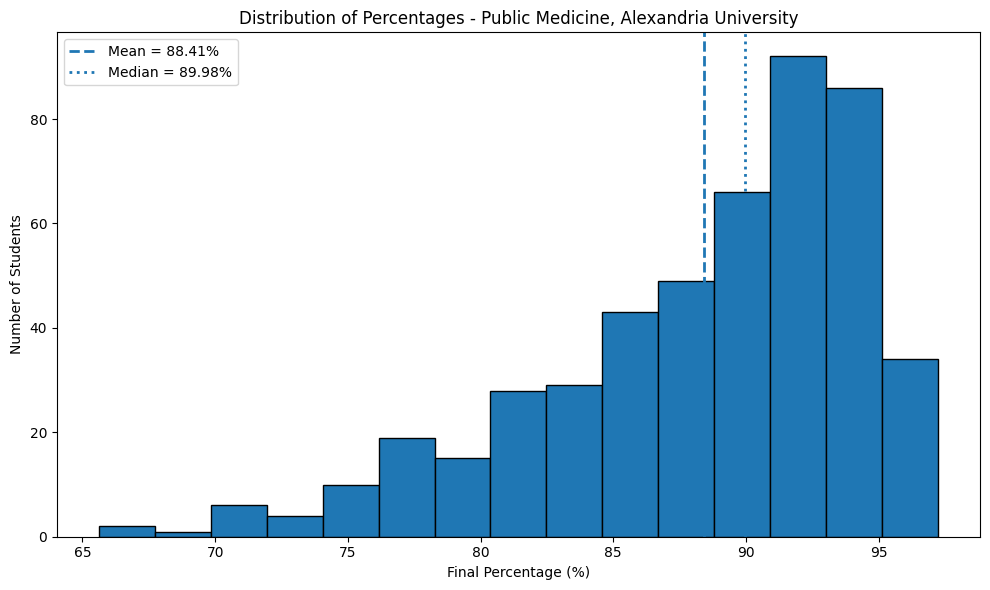

In [8]:
# PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY
# DISTRIBUTION OF PERCENTAGES

plt.figure(figsize=(10, 6))

plt.hist(
    percentages,
    bins=15,
    edgecolor="black"
)

plt.axvline(
    percentages.mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean = {percentages.mean():.2f}%"
)

plt.axvline(
    percentages.median(),
    linestyle=":",
    linewidth=2,
    label=f"Median = {percentages.median():.2f}%"
)

plt.title("Distribution of Percentages - Public Medicine, Alexandria University")
plt.xlabel("Final Percentage (%)")
plt.ylabel("Number of Students")
plt.legend()
plt.tight_layout()
plt.show()


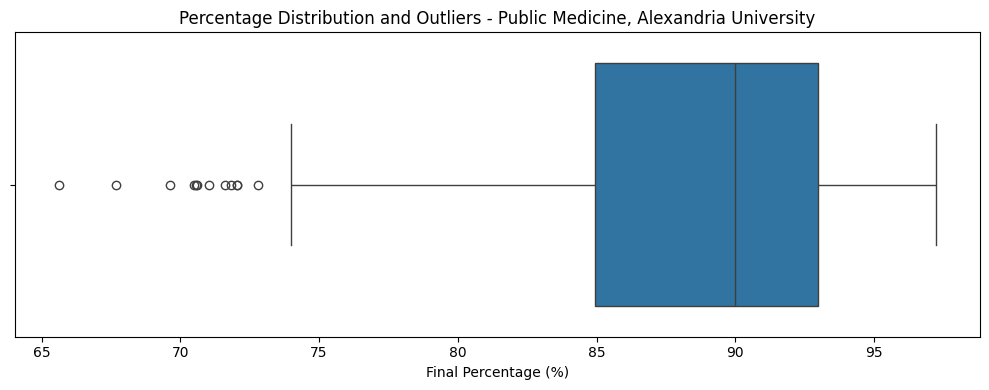

In [9]:
# PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY
# PERCENTAGE BOXPLOT

plt.figure(figsize=(10, 4))

sns.boxplot(x=percentages)

plt.title("Percentage Distribution and Outliers - Public Medicine, Alexandria University")
plt.xlabel("Final Percentage (%)")
plt.tight_layout()
plt.show()


Recorded final grade categories:


,Students,Percentage
التقدير,,
Excellent,362,74.64
Very Good,104,21.44
Good,18,3.71
غ,1,0.21



All recorded values in the grade column:


,Count
التقدير,
Excellent,362
Very Good,104
Good,18
راسب,10
incomplete,4
غ ب,2
غ,1


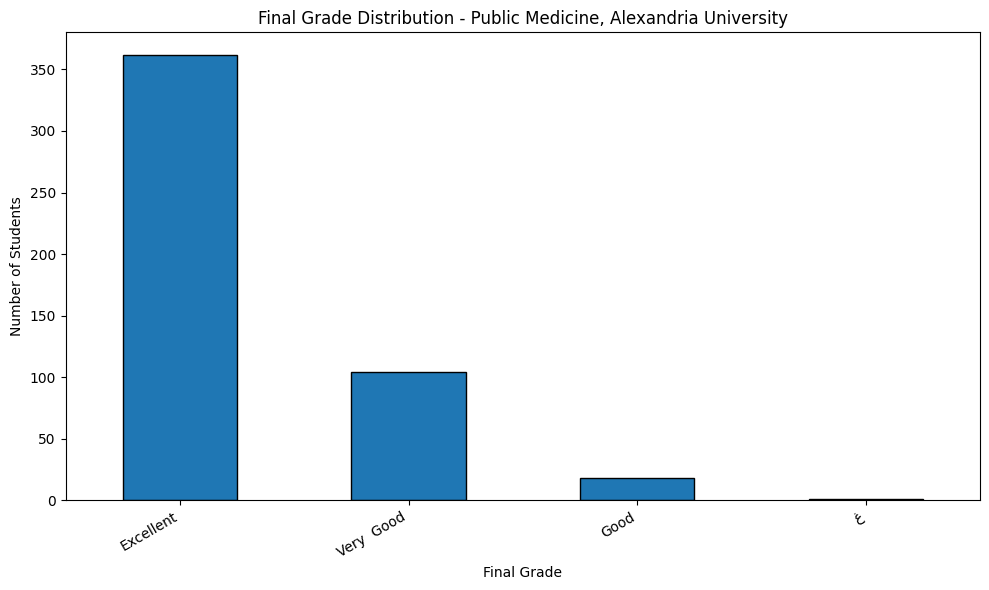

In [10]:
# PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY
# FINAL GRADE DISTRIBUTION

grade_col = "التقدير"

grade_data = df[grade_col].astype("string").str.strip()

# Exclude missing and non-final administrative labels from the grade chart.
# Review excluded values separately instead of silently treating them as grades.
valid_grade_mask = (
    grade_data.notna()
    & ~grade_data.isin(["", "راسب", "غ ب", "محروم", "Incomplete", "incomplete"])
)

grade_counts = grade_data[valid_grade_mask].value_counts()

print("Recorded final grade categories:")
display(
    pd.DataFrame({
        "Students": grade_counts,
        "Percentage": (grade_counts / grade_counts.sum() * 100).round(2)
    })
)

print("\nAll recorded values in the grade column:")
display(grade_data.value_counts(dropna=False).to_frame("Count"))

plt.figure(figsize=(10, 6))

grade_counts.plot(kind="bar", edgecolor="black")

plt.title("Final Grade Distribution - Public Medicine, Alexandria University")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


,Students,Percentage
Percentage Band,,
Below 50%,0,0.00
50–59.99%,0,0.00
60–69.99%,3,0.62
70–79.99%,52,10.74
80–89.99%,187,38.64
90–100%,242,50.00


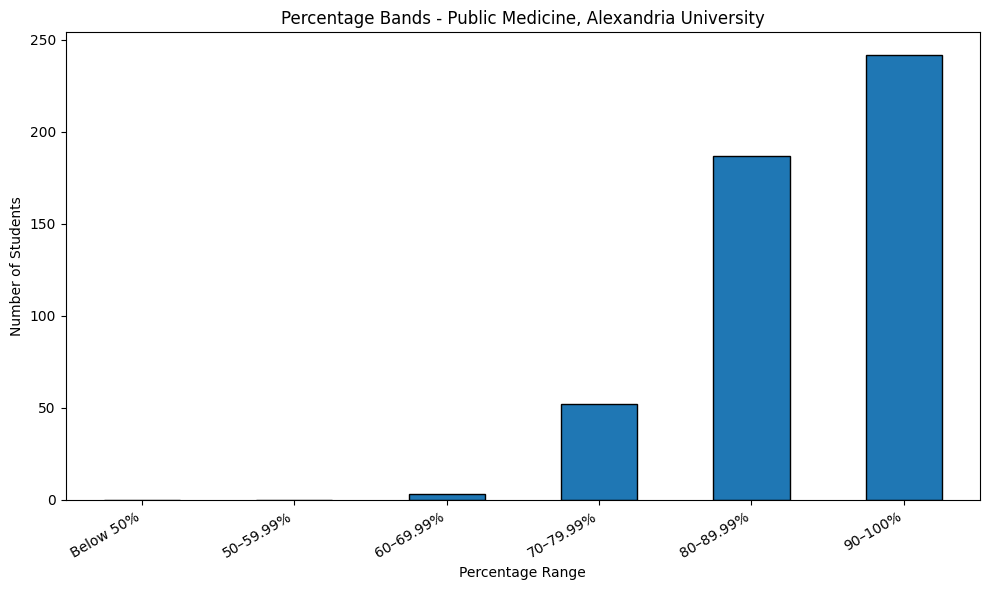

In [11]:
# PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY
# PERCENTAGE BANDS

bins = [0, 50, 60, 70, 80, 90, 100]
labels = [
    "Below 50%",
    "50–59.99%",
    "60–69.99%",
    "70–79.99%",
    "80–89.99%",
    "90–100%"
]

valid_df["Percentage Band"] = pd.cut(
    valid_df["Percentage"],
    bins=bins,
    labels=labels,
    include_lowest=True,
    right=False
)

band_counts = (
    valid_df["Percentage Band"]
    .value_counts(sort=False)
)

band_summary = pd.DataFrame({
    "Students": band_counts,
    "Percentage": (
        band_counts / len(valid_df) * 100
    ).round(2)
})

display(band_summary)

plt.figure(figsize=(10, 6))

band_counts.plot(kind="bar", edgecolor="black")

plt.title("Percentage Bands - Public Medicine, Alexandria University")
plt.xlabel("Percentage Range")
plt.ylabel("Number of Students")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [12]:
# PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY
# PASS / FAIL DATA AUDIT

print("Final grade values:")
display(df["التقدير"].value_counts(dropna=False))

print("\nRows with administrative or failure labels:")
review_mask = (
    df["التقدير"]
    .astype("string")
    .str.contains(
        r"راسب|fail|incomplete|محروم|غ ب",
        case=False,
        na=False
    )
)

review_cols = [
    col for col in ["Seat_Number", "النسبة", "التقدير", "Total 525"]
    if col in df.columns
]

display(df.loc[review_mask, review_cols].head(30))


Final grade values:


,count
التقدير,
Excellent,362
Very Good,104
Good,18
راسب,10
incomplete,4
غ ب,2
غ,1



Rows with administrative or failure labels:


,Seat_Number,النسبة,التقدير,Total 525
1,6,NaN,راسب,راسب
11,37,NaN,غ ب,غ ب
37,97,NaN,راسب,راسب
38,101,NaN,incomplete,incomplete
41,109,NaN,راسب,راسب
118,261,NaN,incomplete,incomplete
200,449,NaN,incomplete,incomplete
209,477,NaN,incomplete,incomplete
249,533,NaN,راسب,راسب
283,645,NaN,راسب,راسب


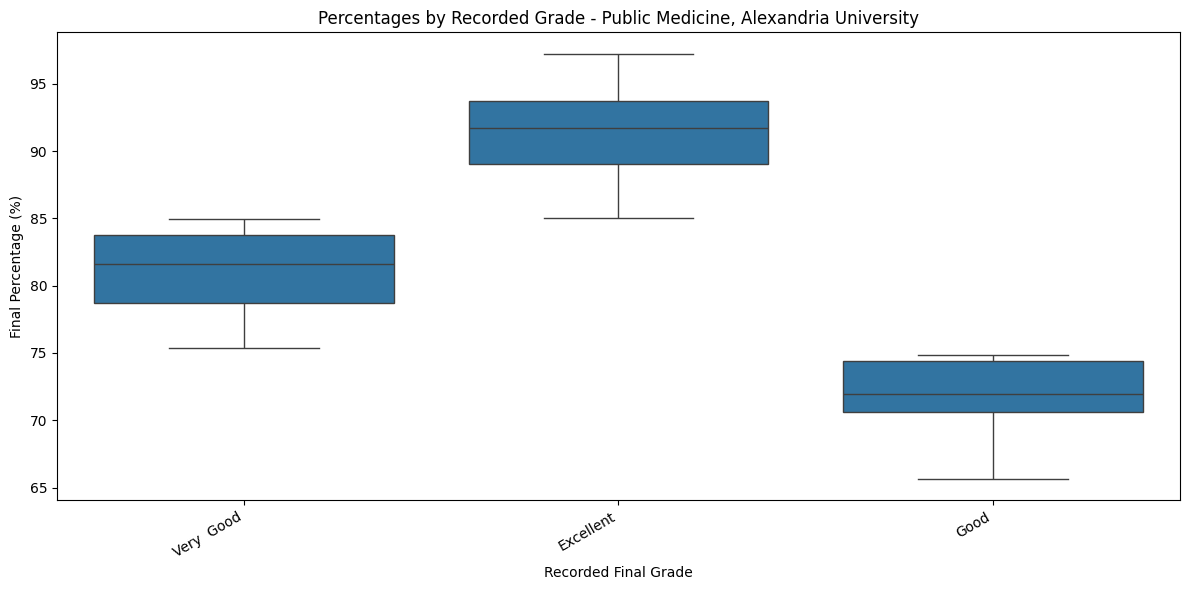

In [13]:
# PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY
# PERCENTAGE BY RECORDED GRADE

grade_percentage_df = valid_df.copy()

grade_percentage_df["Recorded Grade"] = (
    grade_percentage_df["التقدير"]
    .astype("string")
    .str.strip()
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=grade_percentage_df,
    x="Recorded Grade",
    y="Percentage"
)

plt.title("Percentages by Recorded Grade - Public Medicine, Alexandria University")
plt.xlabel("Recorded Final Grade")
plt.ylabel("Final Percentage (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


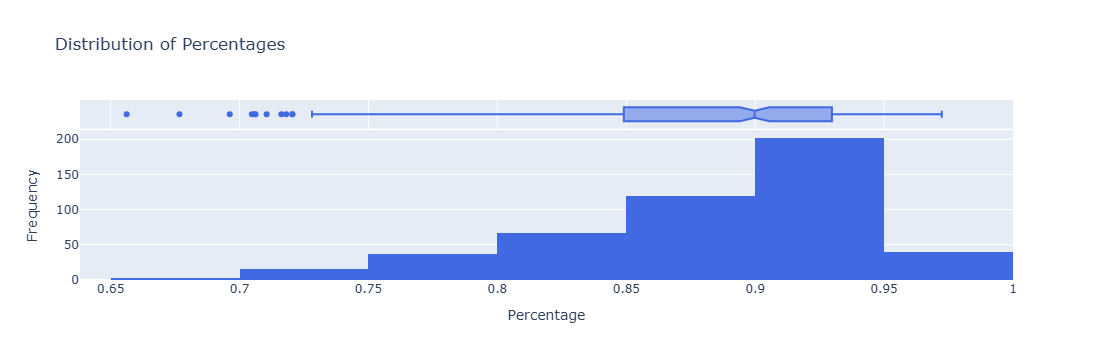

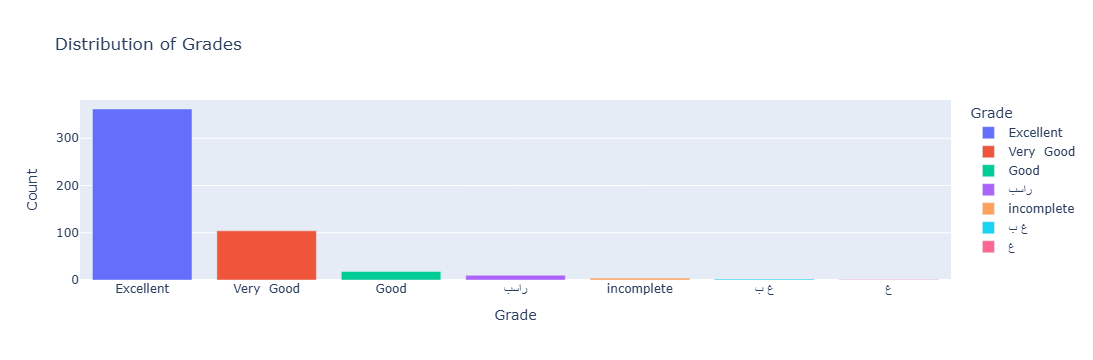

In [ ]:
import pandas as pd
import plotly.express as px

# Clean column names by removing newlines and trailing spaces
df.columns = df.columns.str.replace('\n', ' ').str.strip()

# ==========================================
# 1. Numerical Distribution (Histogram)
# ==========================================
# Convert the percentage column to numeric, forcing invalid parsing to NaN
df['النسبة'] = pd.to_numeric(df['النسبة'], errors='coerce')

# Create an interactive histogram
fig_num = px.histogram(
    df,
    x='النسبة',
    nbins=15,
    title='Distribution of Percentages',
    labels={'النسبة': 'Percentage'},
    marginal='box', # Adds a box plot above the histogram to show outliers
    color_discrete_sequence=['royalblue']
)

# Update layout for better readability
fig_num.update_layout(yaxis_title='Frequency')
fig_num.show()

# ==========================================
# 2. Categorical Distribution (Bar Chart)
# ==========================================
# Calculate frequencies first to sort the bars from highest to lowest
grade_counts = df['التقدير'].value_counts().reset_index()
grade_counts.columns = ['Grade', 'Count'] # Rename columns for the plot

# Create an interactive bar chart
fig_cat = px.bar(
    grade_counts,
    x='Grade',
    y='Count',
    title='Distribution of Grades',
    color='Grade', # Colors the bars based on the grade category
    #text_auto=True # Displays the exact count on top of each bar
)

# Show the plot
fig_cat.show()

In [14]:
# PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY
# FINAL PRELIMINARY SUMMARY

print("=" * 75)
print("PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY")
print("PRELIMINARY ANALYSIS SUMMARY")
print("=" * 75)

print(f"Total records in file       : {len(df)}")
print(f"Valid final percentages     : {len(valid_df)}")
print(f"Mean percentage             : {percentages.mean():.2f}%")
print(f"Median percentage           : {percentages.median():.2f}%")
print(f"Standard deviation          : {percentages.std():.2f}")
print(f"Minimum percentage          : {percentages.min():.2f}%")
print(f"Maximum percentage          : {percentages.max():.2f}%")

print("\nRecorded final grades:")
print(df["التقدير"].value_counts(dropna=False))

print("\nThis is a descriptive analysis of the public medicine cohort.")
print("No comparison with the private cohort has been performed yet.")
print("Pass/fail status and grade classifications require validation.")


PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY
PRELIMINARY ANALYSIS SUMMARY
Total records in file       : 501
Valid final percentages     : 484
Mean percentage             : 88.41%
Median percentage           : 89.98%
Standard deviation          : 6.08
Minimum percentage          : 65.62%
Maximum percentage          : 97.24%

Recorded final grades:
التقدير
Excellent     362
Very  Good    104
Good           18
راسب           10
incomplete      4
غ ب             2
غ               1
Name: count, dtype: int64

This is a descriptive analysis of the public medicine cohort.
No comparison with the private cohort has been performed yet.
Pass/fail status and grade classifications require validation.


In [15]:
# PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY
# VALIDATED GRADE DISTRIBUTION

grade_col = "التقدير"

valid_grade_df = valid_df.copy()
valid_grade_df[grade_col] = (
    valid_grade_df[grade_col].astype("string").str.strip()
)

grade_summary = (
    valid_grade_df[grade_col]
    .value_counts(dropna=False)
    .rename_axis("Grade")
    .reset_index(name="Students")
)

grade_summary["Percentage"] = (
    grade_summary["Students"]
    / len(valid_grade_df) * 100
).round(2)

print("Grade distribution among students with valid percentages:")
display(grade_summary)

print("Total students with valid percentages:", len(valid_df))
print("Total grade counts:", grade_summary["Students"].sum())


Grade distribution among students with valid percentages:


,Grade,Students,Percentage
0,Excellent,362,74.79
1,Very Good,104,21.49
2,Good,18,3.72


Total students with valid percentages: 484
Total grade counts: 484


,Students,Mean,Median,Minimum,Maximum,Std
التقدير,,,,,,
Excellent,362,91.34,91.69,85.00,97.24,3.02
Very Good,104,81.07,81.64,75.38,84.95,2.80
Good,18,71.85,71.93,65.62,74.86,2.57


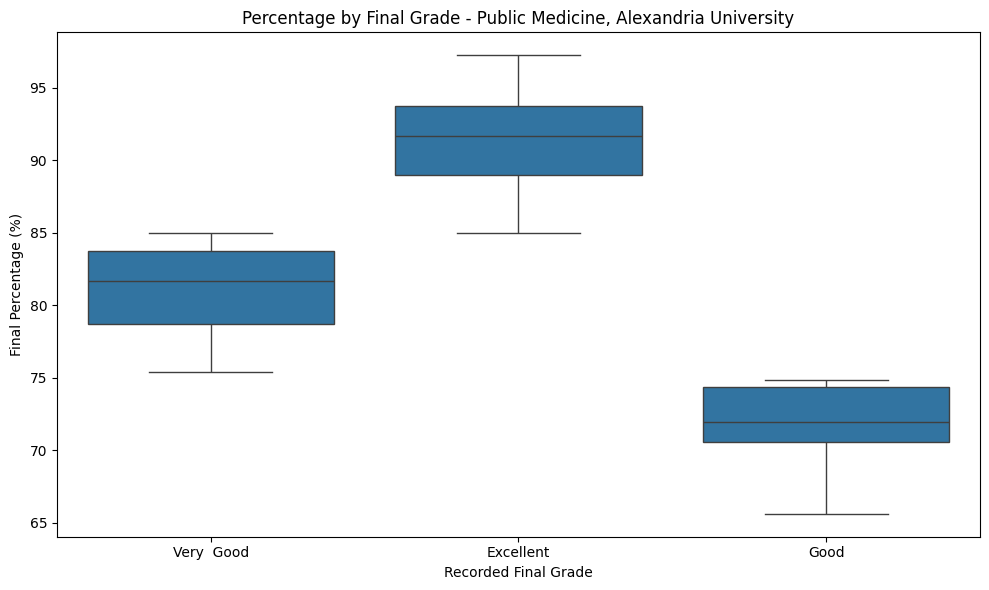

In [16]:
# PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY
# PERCENTAGE SUMMARY BY GRADE

grade_percentage_summary = (
    valid_df.groupby("التقدير", dropna=False)["Percentage"]
    .agg(
        Students="count",
        Mean="mean",
        Median="median",
        Minimum="min",
        Maximum="max",
        Std="std"
    )
    .round(2)
    .sort_values("Mean", ascending=False)
)

display(grade_percentage_summary)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=valid_df,
    x="التقدير",
    y="Percentage"
)

plt.title("Percentage by Final Grade - Public Medicine, Alexandria University")
plt.xlabel("Recorded Final Grade")
plt.ylabel("Final Percentage (%)")
plt.tight_layout()
plt.show()


,Category,Students,Percentage
0,At or above 92.93%,122,25.21
1,Below 92.93%,362,74.79


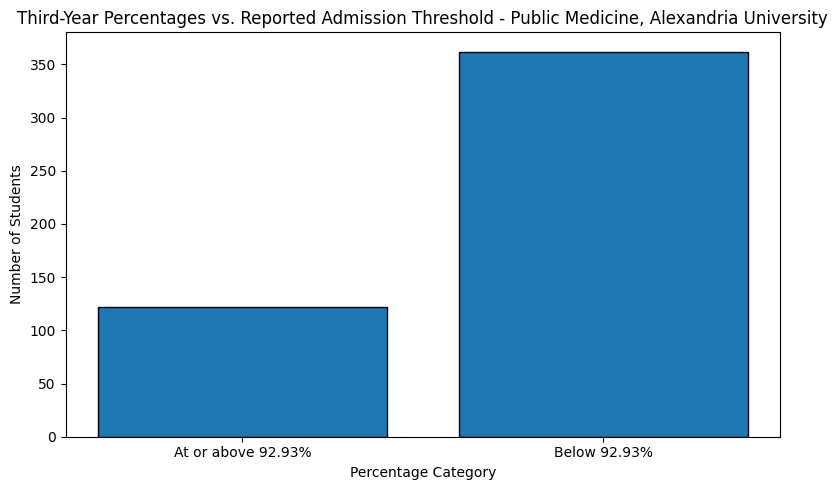

In [17]:
# PUBLIC MEDICINE - ALEXANDRIA UNIVERSITY
# PERCENTAGES RELATIVE TO THE REPORTED ADMISSION THRESHOLD

admission_threshold = 92.93

above_threshold = valid_df["Percentage"] >= admission_threshold
count_above = int(above_threshold.sum())
count_below = int((~above_threshold).sum())

threshold_summary = pd.DataFrame({
    "Category": [
        f"At or above {admission_threshold}%",
        f"Below {admission_threshold}%"
    ],
    "Students": [count_above, count_below],
    "Percentage": [
        count_above / len(valid_df) * 100,
        count_below / len(valid_df) * 100
    ]
})

threshold_summary["Percentage"] = threshold_summary["Percentage"].round(2)

display(threshold_summary)

plt.figure(figsize=(8, 5))

plt.bar(
    threshold_summary["Category"],
    threshold_summary["Students"],
    edgecolor="black"
)

plt.title("Third-Year Percentages vs. Reported Admission Threshold - Public Medicine, Alexandria University")
plt.xlabel("Percentage Category")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()
